# A latent crossing

**1,000 MD steps per frame.** Frozen 2D AE trained on one trajectory per source (four sources; seed 123). We inspect held-out low-T node network 47 and stiffness network 106. These are **AE reconstructions, not rollouts**. The pair was selected after inspecting crossings; it is an illustrative case, not a population estimate.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/lss').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from lss.plotting import apply_editorial_style, style_axes
PLOT_THEME = 'light'
apply_editorial_style(PLOT_THEME)
BASE = ROOT / 'notebooks/results/all4_coverage_1000'
RUN = BASE / 'all4_one_each_retry_v5_validation30'
latents = pd.read_csv(RUN / 'test/latents.csv')
predictions = pd.read_csv(RUN / 'test/per_network.csv')
boxes = pd.read_csv(BASE / 'notebook01_crossing_pair/raw_box_motion.csv')
IDS = {'node_low': 47, 'stiffness_low': 106}
NAMES = {'node_low': 'Node 47', 'stiffness_low': 'Stiffness 106'}
COLORS = {'node_low': '#2878a4', 'stiffness_low': '#ce643d'}
STYLES = {'node_low': '-', 'stiffness_low': '--'}
FRAME = 33
paths, physical, recon = {}, {}, {}
for source, network in IDS.items():
    paths[source] = latents.loc[(latents.source == source) & (latents.trajectory_id == network) & (latents.frame < 100)].sort_values('frame').set_index('frame')
    physical[source] = boxes.loc[(boxes.source == source) & (boxes.trajectory_id == network) & (boxes.frame < 100)].sort_values('frame').set_index('frame')
    recon[source] = predictions.loc[(predictions['mode'] == 'ae_reconstruction') & (predictions.source == source) & (predictions.trajectory_id == network) & (predictions.frame < 100)].sort_values('frame').set_index('frame')
    assert paths[source].index.tolist() == physical[source].index.tolist() == recon[source].index.tolist() == list(range(100))
distance = np.linalg.norm(paths['node_low'].loc[FRAME, ['z0', 'z1']].to_numpy(dtype=float) - paths['stiffness_low'].loc[FRAME, ['z0', 'z1']].to_numpy(dtype=float))

## Same path, different timing

Raw coordinates: no alignment, centering, rotation or rescaling. The right panel zooms around frame 33; matching a geometric path does not mean matching its timing.

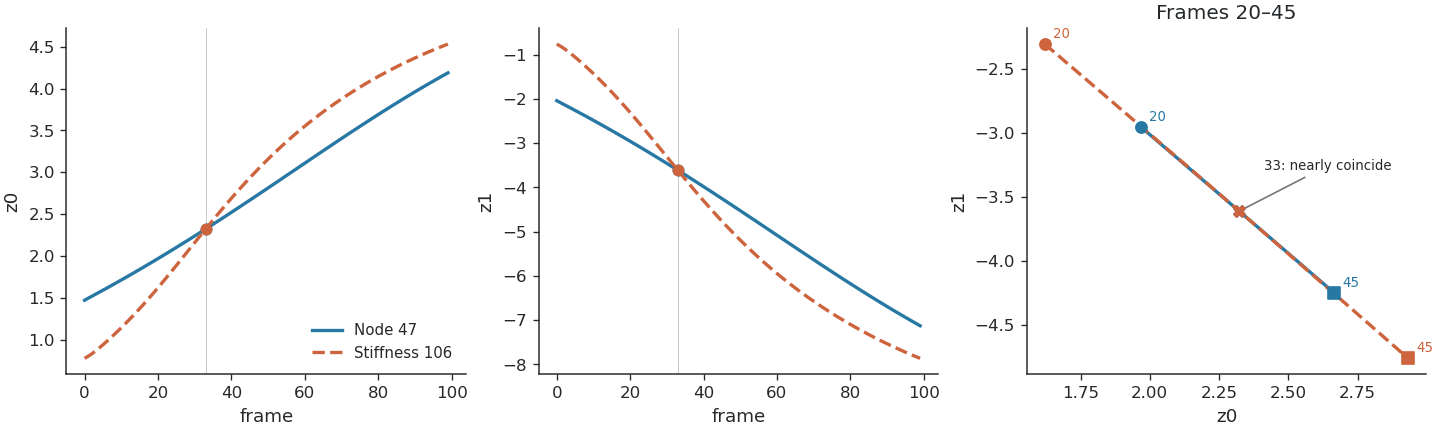

Frame 33: raw 2D latent separation = 0.000173.


,network,z0,z1
0,Node 47,2.322643,-3.612332
1,Stiffness 106,2.322780,-3.612437


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for source, g in paths.items():
    color, ls = COLORS[source], STYLES[source]
    for ax, coordinate in zip(axes[:2], ['z0', 'z1']):
        ax.plot(g.index, g[coordinate], color=color, ls=ls, label=NAMES[source])
        ax.scatter(FRAME, g.loc[FRAME, coordinate], color=color, s=38, zorder=4)
        ax.axvline(FRAME, color='#999999', lw=.6, alpha=.3)
        style_axes(ax, xlabel='frame', ylabel=coordinate, legend=(ax is axes[0]))
    near = g.loc[20:45]
    axes[2].plot(near.z0, near.z1, color=color, ls=ls, lw=2)
    for frame, marker in [(20, 'o'), (33, 'X'), (45, 's')]:
        axes[2].scatter(g.loc[frame, 'z0'], g.loc[frame, 'z1'], color=color, marker=marker, s=45, zorder=4)
        if frame != 33:
            axes[2].annotate(str(frame), (g.loc[frame, 'z0'], g.loc[frame, 'z1']), xytext=(5, 4), textcoords='offset points', fontsize=8, color=color)
axes[2].annotate('33: nearly coincide', paths['node_low'].loc[33, ['z0', 'z1']], xytext=(15, 25), textcoords='offset points', fontsize=8, arrowprops={'arrowstyle': '-', 'color': '#777777'})
style_axes(axes[2], xlabel='z0', ylabel='z1')
axes[2].set_title('Frames 20–45')
plt.show()
print(f'Frame 33: raw 2D latent separation = {distance:.6f}.')
display(pd.DataFrame([{'network': NAMES[s], 'z0': g.loc[FRAME, 'z0'], 'z1': g.loc[FRAME, 'z1']} for s, g in paths.items()]).round(6))

## Why they meet

Different starting positions plus different amounts of movement produce almost the same coordinate at frame 33. This is a decomposition of the encoded paths, not proof of a shared physical observable.

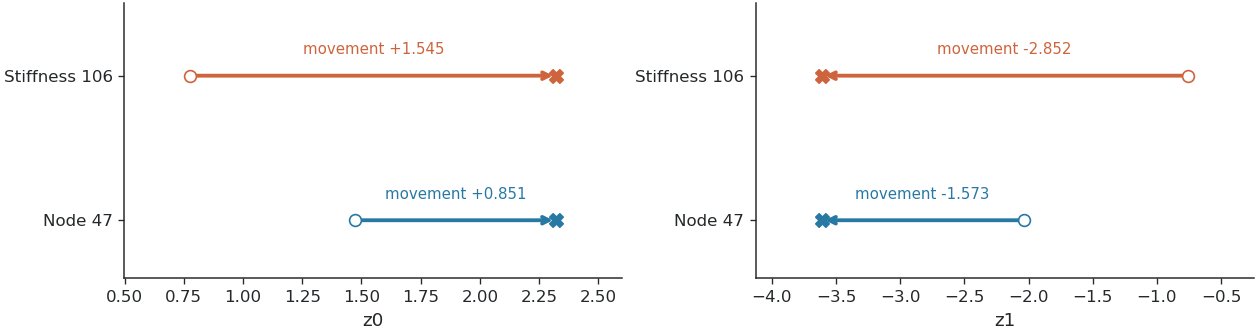

,network,coordinate,initial,movement to frame 33,frame 33
0,Node 47,z0,1.471606,0.851036,2.322643
1,Stiffness 106,z0,0.777404,1.545375,2.322780
2,Node 47,z1,-2.039196,-1.573136,-3.612332
3,Stiffness 106,z1,-0.760612,-2.851826,-3.612437


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.8), constrained_layout=True)
rows = []
for ax, coordinate in zip(axes, ['z0', 'z1']):
    for row, (source, g) in enumerate(paths.items()):
        start, end = float(g.loc[0, coordinate]), float(g.loc[FRAME, coordinate])
        ax.annotate('', xy=(end, row), xytext=(start, row), arrowprops={'arrowstyle': '->', 'color': COLORS[source], 'lw': 2.3})
        ax.scatter(start, row, facecolor='white', edgecolor=COLORS[source], s=50, zorder=3)
        ax.scatter(end, row, color=COLORS[source], marker='X', s=65, zorder=3)
        ax.text((start+end)/2, row+.15, f'movement {end-start:+.3f}', ha='center', color=COLORS[source], fontsize=9)
        rows.append({'network': NAMES[source], 'coordinate': coordinate, 'initial': start, 'movement to frame 33': end-start, 'frame 33': end})
    ax.set_yticks([0, 1], [NAMES[s] for s in paths])
    ax.set_ylim(-.4, 1.5)
    ax.margins(x=.18)
    style_axes(ax, xlabel=coordinate, ylabel='')
plt.show()
display(pd.DataFrame(rows).round(6))

## Different physical responses

Left: raw simulation-box height change from frame 0. Right: **the same boundary-node p-ratio estimator for truth and AE**, using fixed frame-0 side nodes and each frame's cumulative deformation (no temporal fit). Raw box and boundary-node measurements are kept separate.

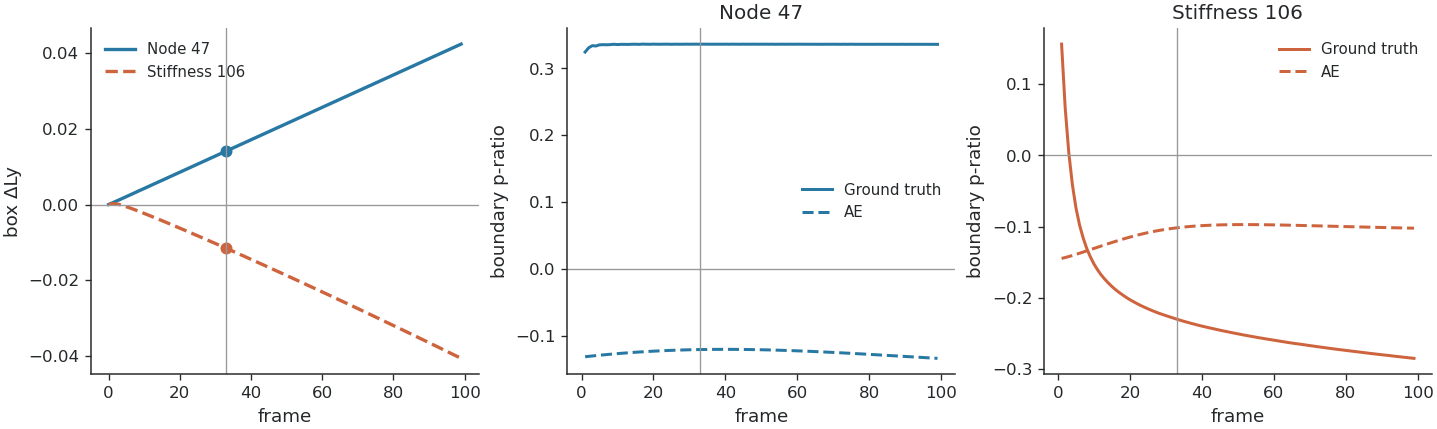

Frame 33 · valid 2/2 networks


,network,frame,box ΔLy,box x-strain,true boundary p-ratio,AE boundary p-ratio
0,Node 47,33,0.014122,-0.0033,0.336175,-0.120635
1,Stiffness 106,33,-0.011566,-0.0033,-0.229816,-0.101643


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for source, g in physical.items():
    axes[0].plot(g.index, g.delta_Ly, color=COLORS[source], ls=STYLES[source], label=NAMES[source])
    axes[0].scatter(FRAME, g.loc[FRAME, 'delta_Ly'], color=COLORS[source], s=38)
axes[0].axvline(FRAME, color='#999999', lw=.8)
axes[0].axhline(0, color='#999999', lw=.8)
style_axes(axes[0], xlabel='frame', ylabel='box ΔLy', legend=True)
for ax, (source, g) in zip(axes[1:], recon.items()):
    g = g.loc[1:99]
    ax.plot(g.index, g.true_p_ratio, color=COLORS[source], label='Ground truth', lw=1.8)
    ax.plot(g.index, g.pred_p_ratio, color=COLORS[source], ls='--', label='AE', lw=1.8)
    ax.axhline(0, color='#999999', lw=.8)
    ax.axvline(FRAME, color='#999999', lw=.8)
    ax.set_title(NAMES[source])
    style_axes(ax, xlabel='frame', ylabel='boundary p-ratio', legend=True)
plt.show()
summary = pd.DataFrame([{'network': NAMES[s], 'frame': FRAME, 'box ΔLy': physical[s].loc[FRAME, 'delta_Ly'], 'box x-strain': physical[s].loc[FRAME, 'strain_x'], 'true boundary p-ratio': g.loc[FRAME, 'true_p_ratio'], 'AE boundary p-ratio': g.loc[FRAME, 'pred_p_ratio']} for s, g in recon.items()])
assert np.isfinite(summary.select_dtypes('number').to_numpy()).all()
print('Frame 33 · valid 2/2 networks')
display(summary.round(6))

## Takeaway

These trajectories nearly share a latent path, but traverse it at different rates. Their meeting does **not** mean equal y-deformation or equal p-ratio: one expands in y and the other contracts. The AE predicts contraction for both here, so its reference-graph context does not recover the opposite signs in this example.

Frozen run: `all4_one_each_retry_v5_validation30`, seed 123, training job 4685259; held-out-development IDs 47/106. Box-source paths and hashes: `notebooks/results/all4_coverage_1000/notebook01_crossing_pair/metadata.json`. No retraining or final-test evaluation.

## Trained on twenty

Same four sources and seed, now twenty trajectories per source. First, the **same physical pair** as above, in this encoder's raw coordinates. The encoders have independent coordinate systems; distances should not be compared across models as a performance score.

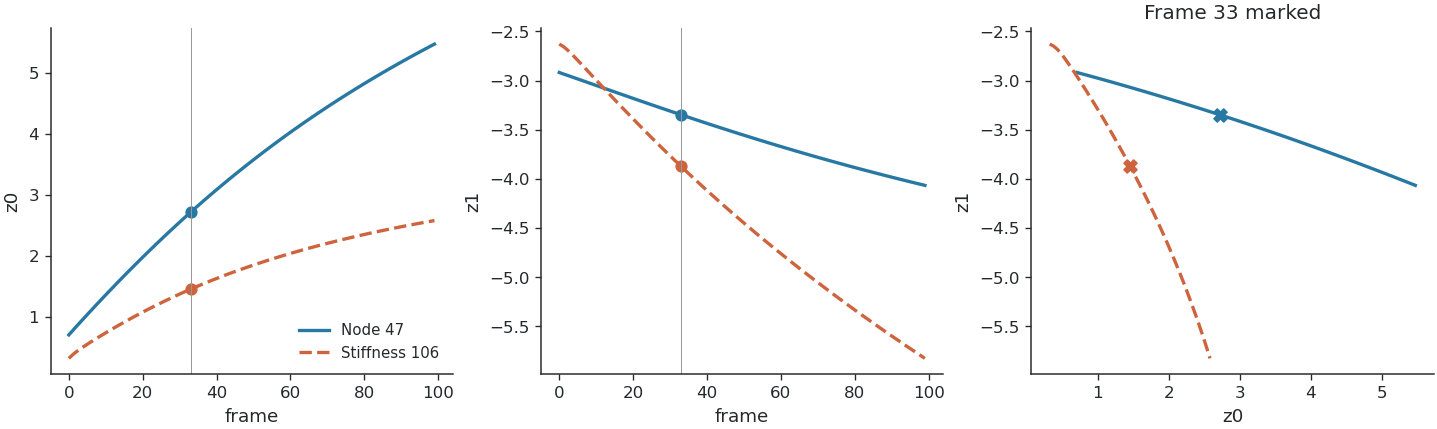

Same pair, frame 33; valid 2/2.


,network,z0,z1,true p-ratio,AE p-ratio
0,Node 47,2.719350,-3.347738,0.336175,0.225485
1,Stiffness 106,1.459135,-3.872748,-0.229816,-0.109867


In [5]:
RUN20 = BASE / 'all4_twenty_each_retry_v5_validation30'
latent20 = pd.read_csv(RUN20 / 'test/latents.csv')
prediction20 = pd.read_csv(RUN20 / 'test/per_network.csv')
ae20 = prediction20.loc[prediction20['mode'].eq('ae_reconstruction')].copy()
def get_path(table, source, network):
    return table.loc[table.source.eq(source) & table.trajectory_id.eq(network)].sort_values('frame').set_index('frame')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
pair_values = []
for source, network in IDS.items():
    g = get_path(latent20, source, network).loc[:99]
    for ax, coordinate in zip(axes[:2], ['z0', 'z1']):
        ax.plot(g.index, g[coordinate], color=COLORS[source], ls=STYLES[source], label=NAMES[source])
        ax.scatter(33, g.loc[33, coordinate], color=COLORS[source], s=40)
        ax.axvline(33, color='#999999', lw=.6)
        style_axes(ax, xlabel='frame', ylabel=coordinate, legend=(ax is axes[0]))
    axes[2].plot(g.z0, g.z1, color=COLORS[source], ls=STYLES[source])
    axes[2].scatter(g.loc[33, 'z0'], g.loc[33, 'z1'], color=COLORS[source], marker='X', s=60)
    p = get_path(ae20, source, network).loc[33]
    pair_values.append({'network': NAMES[source], 'z0': g.loc[33, 'z0'], 'z1': g.loc[33, 'z1'], 'true p-ratio': p.true_p_ratio, 'AE p-ratio': p.pred_p_ratio})
style_axes(axes[2], xlabel='z0', ylabel='z1')
axes[2].set_title('Frame 33 marked')
plt.show()
same_pair20 = pd.DataFrame(pair_values)
print('Same pair, frame 33; valid 2/2.')
display(same_pair20.round(6))

## Find a new near-meeting

Search all 80 × 80 held-out low-T cross-family pairs, at the **same time**, over frames 1–99. Select the closest pair in raw 2D latent distance at a saved frame, without using p-ratio. Also check z0 crossings between adjacent frames: a z0 crossing alone is not a full 2D intersection. Interpolated times below describe straight segments between saved codes, not newly encoded states.

Checked 6,400 pairs × 99 saved frames. Closest: node 102, stiffness 51, frame 2; 2D distance 0.000750.
2,525 strict z0 crossings; smallest remaining z1 gap 0.000072. This is a near-meeting, not an exact 2D intersection.


,node_id,stiffness_id,interpolated_frame,absolute_z1_gap
1923,102,51,2.032123,0.000072


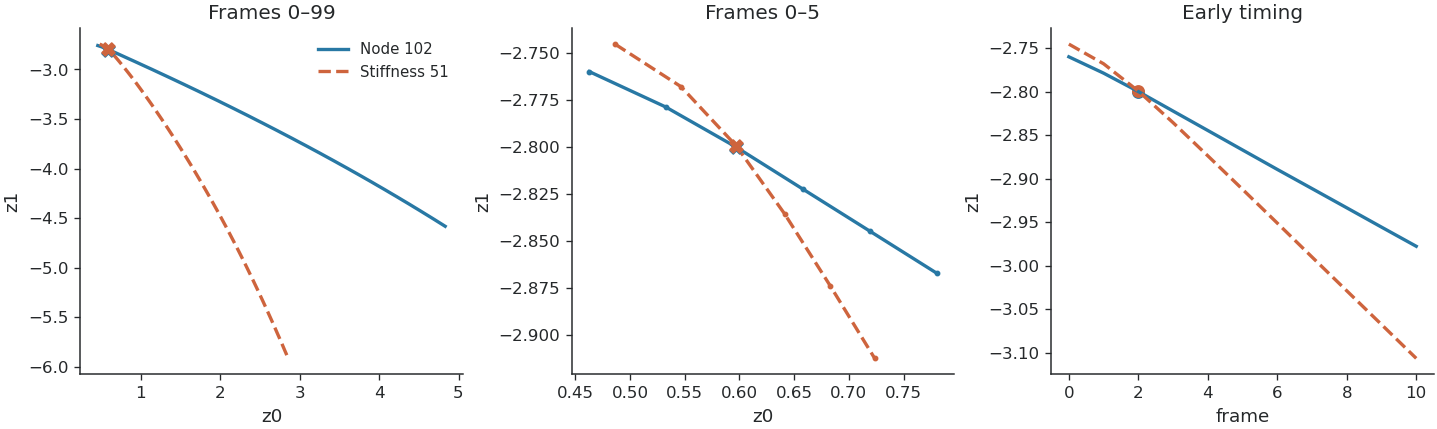

In [6]:
sources = ['node_low', 'stiffness_low']
ids20, arrays = {}, {}
for source in sources:
    selected = latent20.loc[latent20.source.eq(source) & latent20.frame.between(0, 99)]
    ids20[source] = np.sort(selected.trajectory_id.unique())
    arrays[source] = np.stack([get_path(selected, source, int(i))[['z0', 'z1']].to_numpy() for i in ids20[source]])
    assert arrays[source].shape == (80, 100, 2)
delta = arrays[sources[0]][:, None, :, :] - arrays[sources[1]][None, :, :, :]
distances = np.linalg.norm(delta, axis=-1)
distances[:, :, 0] = np.inf
i, j, near_frame = np.unravel_index(np.argmin(distances), distances.shape)
NEAR_IDS = {sources[0]: int(ids20[sources[0]][i]), sources[1]: int(ids20[sources[1]][j])}
near_distance = float(distances[i, j, near_frame])
d0, d1 = delta[:, :, :-1, 0], delta[:, :, 1:, 0]
ii, jj, tt = np.where((d0*d1 < 0) & (np.arange(99)[None, None, :] >= 1))
alpha = -d0[ii, jj, tt] / (d1[ii, jj, tt]-d0[ii, jj, tt])
z1_gap = delta[ii, jj, tt, 1]*(1-alpha) + delta[ii, jj, tt+1, 1]*alpha
crossings20 = pd.DataFrame({'node_id': ids20[sources[0]][ii], 'stiffness_id': ids20[sources[1]][jj], 'interpolated_frame': tt+alpha, 'absolute_z1_gap': np.abs(z1_gap)})
print(f'Checked 6,400 pairs × 99 saved frames. Closest: node {NEAR_IDS[sources[0]]}, stiffness {NEAR_IDS[sources[1]]}, frame {near_frame}; 2D distance {near_distance:.6f}.')
print(f'{len(crossings20):,} strict z0 crossings; smallest remaining z1 gap {crossings20.absolute_z1_gap.min():.6f}. This is a near-meeting, not an exact 2D intersection.')
display(crossings20.nsmallest(1, 'absolute_z1_gap').round(6))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
for source, network in NEAR_IDS.items():
    g = get_path(latent20, source, network)
    label = f'{"Node" if source == "node_low" else "Stiffness"} {network}'
    axes[0].plot(g.loc[:99].z0, g.loc[:99].z1, color=COLORS[source], ls=STYLES[source], label=label)
    axes[1].plot(g.loc[:5].z0, g.loc[:5].z1, color=COLORS[source], ls=STYLES[source], marker='.', markersize=5)
    for ax in axes[:2]:
        ax.scatter(g.loc[near_frame, 'z0'], g.loc[near_frame, 'z1'], color=COLORS[source], marker='X', s=60, zorder=4)
    axes[2].plot(g.loc[:10].index, g.loc[:10].z1, color=COLORS[source], ls=STYLES[source])
    axes[2].scatter(near_frame, g.loc[near_frame, 'z1'], color=COLORS[source], s=45)
for ax in axes[:2]:
    style_axes(ax, xlabel='z0', ylabel='z1', legend=(ax is axes[0]))
axes[0].set_title('Frames 0–99')
axes[1].set_title('Frames 0–5')
axes[2].set_title('Early timing')
style_axes(axes[2], xlabel='frame', ylabel='z1')
plt.show()

## Does reconstruction agree?

Ground truth and AE use the **same fixed-boundary endpoint estimator** at each frame, with no latent-to-p-ratio regression or temporal fit. Early ratios can amplify small errors because x-deformation is small. The final frame is included in the table; this pair was selected by latent proximity, not response accuracy.

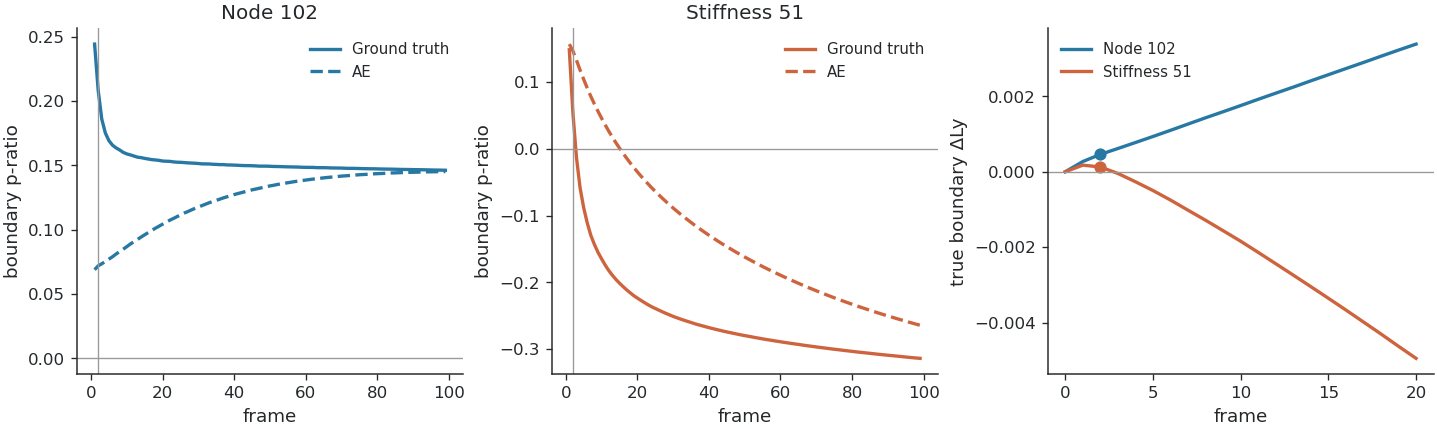

Valid 6/6 network–frame evaluations.


,network,frame,true p-ratio,AE p-ratio
0,Node 102,2,0.208412,0.071937
1,Node 102,33,0.151103,0.120962
2,Node 102,199,0.141390,0.137291
3,Stiffness 51,2,0.054242,0.146651
4,Stiffness 51,33,-0.256620,-0.101847
5,Stiffness 51,199,-0.352315,-0.362360


,source,frame,AE p-ratio R²,valid/total
0,node_low,2,-11.7526,80/80
1,node_low,33,0.9618,80/80
2,node_low,99,0.9847,80/80
3,node_low,199,0.9823,80/80
4,stiffness_low,2,-3.1681,80/80
5,stiffness_low,33,0.7153,80/80
6,stiffness_low,99,0.9738,80/80
7,stiffness_low,199,0.9430,80/80


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), constrained_layout=True)
response_rows = []
for ax, (source, network) in zip(axes[:2], NEAR_IDS.items()):
    g = get_path(ae20, source, network)
    label = f'{"Node" if source == "node_low" else "Stiffness"} {network}'
    ax.plot(g.loc[1:99].index, g.loc[1:99].true_p_ratio, color=COLORS[source], label='Ground truth')
    ax.plot(g.loc[1:99].index, g.loc[1:99].pred_p_ratio, color=COLORS[source], ls='--', label='AE')
    ax.axvline(near_frame, color='#999999', lw=.8)
    ax.axhline(0, color='#999999', lw=.8)
    ax.set_title(label)
    style_axes(ax, xlabel='frame', ylabel='boundary p-ratio', legend=True)
    physical_path = get_path(latent20, source, network).loc[:20]
    axes[2].plot(physical_path.index, physical_path.y_deformation, color=COLORS[source], label=label)
    axes[2].scatter(near_frame, physical_path.loc[near_frame, 'y_deformation'], color=COLORS[source], s=40)
    for f in [int(near_frame), 33, 199]:
        response_rows.append({'network': label, 'frame': f, 'true p-ratio': g.loc[f, 'true_p_ratio'], 'AE p-ratio': g.loc[f, 'pred_p_ratio']})
axes[2].axhline(0, color='#999999', lw=.8)
style_axes(axes[2], xlabel='frame', ylabel='true boundary ΔLy', legend=True)
plt.show()
near_response = pd.DataFrame(response_rows)
assert np.isfinite(near_response[['true p-ratio', 'AE p-ratio']]).all().all()
print(f'Valid {len(near_response)}/{len(near_response)} network–frame evaluations.')
display(near_response.round(6))

# Whole held-out low-T cohort: do not infer model quality from a selected pair.
accuracy_rows = []
for source in sources:
    for frame in [int(near_frame), 33, 99, 199]:
        g = ae20.loc[ae20.source.eq(source) & ae20.frame.eq(frame)]
        valid = np.isfinite(g[['true_p_ratio', 'pred_p_ratio']]).all(axis=1)
        v = g.loc[valid]
        sst = ((v.true_p_ratio-v.true_p_ratio.mean())**2).sum()
        assert sst > 0
        r2 = 1-((v.true_p_ratio-v.pred_p_ratio)**2).sum()/sst
        accuracy_rows.append({'source': source, 'frame': frame, 'AE p-ratio R²': r2, 'valid/total': f'{len(v)}/{len(g)}'})
accuracy20 = pd.DataFrame(accuracy_rows)
display(accuracy20.round(4))

## What changes with twenty?

The original pair no longer nearly coincides at frame 33. Another pair nearly meets early, then follows different latent paths and develops different mechanical responses. Its early AE p-ratios are imperfect, but its final p-ratios are much more accurate. A near-meeting still does **not** identify a universal physical state: the decoder also receives each graph's static reference context.

This is a frozen-checkpoint, single-seed diagnostic, not retraining or autonomous rollout. The cohort table provides reconstruction accuracy beyond the selected example.

In [8]:
# Compact audit artifacts; no figure exports.
import hashlib
import json
audit_dir = BASE / 'notebook10_twenty_crossings'
audit_dir.mkdir(exist_ok=True)
crossings20.to_csv(audit_dir / 'synchronous_z0_crossings.csv', index=False)
near_response.to_csv(audit_dir / 'selected_pair_response.csv', index=False)
accuracy20.to_csv(audit_dir / 'cohort_ae_accuracy.csv', index=False)
inputs = [RUN20/'recipe.json', RUN20/'test/latents.csv', RUN20/'test/per_network.csv', ROOT/'notebooks/dynamics/10_latent_crossing_and_response.ipynb']
metadata = {'run': str(RUN20.relative_to(ROOT)), 'seed': 123, 'sources': sources, 'heldout_ids': {s: ids20[s].tolist() for s in sources}, 'frames_searched': [1, 99], 'selection': 'minimum raw 2D same-saved-frame distance across cross-family pairs; no response selection', 'selected_ids': NEAR_IDS, 'selected_frame': int(near_frame), 'selected_distance': near_distance, 'strict_z0_crossings': len(crossings20), 'estimator': ae20.p_ratio_method.unique().tolist(), 'hashes': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in inputs}, 'training_performed': False, 'final_test_used': False}
(audit_dir / 'metadata.json').write_text(json.dumps(metadata, indent=2)+'\n')

2981